# 28. Quét ngưỡng δ của hàm Huber

Tuần 3 cố định ngưỡng Huber bằng 1,0 mà không quét. Với dữ liệu đã chuẩn hóa theo tập huấn luyện, ngưỡng 1,0 đặt ranh giới giữa vùng bình phương và vùng tuyến tính ở đúng một độ lệch chuẩn của kênh. Đây là lựa chọn hợp lý nhưng chưa được kiểm chứng.

Thiết kế:

- Lưới ba ngưỡng 0,5; 1,0; 2,0, mỗi ngưỡng năm hạt giống, cùng giao thức chính.
- Chọn ngưỡng theo MSE_obs trung bình trên tập kiểm định, đúng tiêu chí đã khóa ở notebook 27. Tập kiểm tra không tham gia vào việc chọn.
- Ngưỡng 1,0 được huấn luyện lại trong thư mục này vì các lần chạy cũ không ghi MAE_obs trên tập kiểm định. Lần huấn luyện lại này đồng thời là một phép thử tái lập: trung bình MSE_obs kiểm tra phải nằm sát giá trị 0,433972 của tuần 3.
- Nếu ngưỡng được chọn khác 1,0, phép bắt cặp với ngưỡng 1,0 trên tập kiểm tra chỉ được ghi là mô tả.

Mười lăm lần huấn luyện, khoảng mười hai đến mười lăm phút trên bộ xử lý đồ họa. Lần nào đã có tệp kết quả thì được đọc lại.

> Kết quả ghi vào thư mục con `Output/processed/w4_35_quet_delta_huber`.

> **Vị trí trong chuỗi tái lập:** notebook 28 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 27-Khai_bao_truoc_va_cong_kiem_tra.
>
> **Thư mục kết quả:** `Output/processed/w4_35_quet_delta_huber/`.
>
> **Mã định danh nội bộ:** `W4_35`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w4_35_quet_delta_huber"  #@param {type:"string"}
DANH_SACH_DELTA = "0.5,1.0,2.0"  #@param {type:"string"}
SO_THAM_SO_NLINEAR = 876  #@param {type:"integer"}
MSE_B_HUBER_TUAN_3 = 0.433972  #@param {type:"number"}
N_BOOT = 5000  #@param {type:"integer"}
HAT_GIONG_LAY_MAU = 0  #@param {type:"integer"}
MUC_ALPHA = 0.05  #@param {type:"number"}
MSE_MOC_KY_VONG = 0.5787542076552471  #@param {type:"number"}
TONG_DIEM_KY_VONG = 136752  #@param {type:"integer"}
CHAY_LAI_TU_DAU = False  #@param {type:"boolean"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 5      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

# Mọi sổ tay tuần 4 dùng năm hạt giống, nên giá trị dưới đây ghi đè tham số chung.
N_SEEDS = 5
import os, sys, json, time, random, datetime, platform, importlib, subprocess, hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

# Tệp khai báo trước họ kiểm định của tuần 4, do W4_34 ghi.
KHAI_BAO_DIR = OUT / "processed" / "w4_34_khai_bao_truoc_va_cong_tuan_4"
TEP_KHAI_BAO = KHAI_BAO_DIR / "W4_khai_bao_ho_kiem_dinh.json"

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
TEN_TINH = list(meta.get("static", []))
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| đặc trưng tĩnh:", TEN_TINH)

Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w4_35_quet_delta_huber
Số kênh     : 37 | đặc trưng tĩnh: ['Age', 'Gender', 'Height', 'ICUType_1', 'ICUType_2', 'ICUType_3', 'ICUType_4']


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)

timestamp    2026-10-14T19:00:55
run_tag      w4_35_quet_delta_huber
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    fig.savefig(duong.with_suffix(".pdf"))
    print("Đã lưu", duong, "và bản vector pdf")
    return duong


print("Đã đặt quy ước trình bày hình")

Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm dùng chung

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tuần 4 chỉ dùng neo B trên giao thức chính. Định nghĩa A được giữ để kiểm tra chéo với tuần 3.
NEO_HOP_LE = ("A", "B")


class LinearFamily(nn.Module):
    # Lớp bao trùm DLinear và NLinear, chép nguyên công thức của tuần 3 cho hai neo A và B.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="B",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)

    def compute_anchor(self, x, mask):
        if self.anchor == "A":
            return x[:, -1, :]
        val, _ = last_observed(x, mask)
        return val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def phan_du(self, x, mask):
        # Phần mô hình học, tính trên chuỗi đã trừ neo; trả về kích thước lô, H, C.
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1), a

    def forward(self, x, mask):
        z, a = self.phan_du(x, mask)
        return z + a.unsqueeze(1)


class LinearFamilyTinh(LinearFamily):
    # Nhánh tĩnh đúng như giả thuyết H2 của tuần 1: hai hệ số vô hướng alpha và beta là hàm
    # Affine của vectơ đặc trưng tĩnh s, nên số tham số thêm đúng bằng 2(d_s + 1).
    # Điều chỉnh đặt lên phần dư sau khi trừ neo, nên neo B giữ nguyên mức nền của từng hồ sơ:
    # y_hat = a + (1 + alpha(s)) * z + beta(s).
    # Hai lớp tĩnh khởi tạo bằng không, lớp tuyến tính chính được tạo trước với cùng hạt giống,
    # Nên tại bước đầu mô hình trùng khít mô hình nền cùng hạt giống.
    def __init__(self, seq_len, pred_len, n_channels, d_static, kind="nlinear", anchor="B", **kw):
        super().__init__(seq_len, pred_len, n_channels, kind=kind, anchor=anchor, **kw)
        self.d_static = int(d_static)
        self.static_alpha = nn.Linear(self.d_static, 1)
        self.static_beta = nn.Linear(self.d_static, 1)
        for lop in (self.static_alpha, self.static_beta):
            nn.init.zeros_(lop.weight)
            nn.init.zeros_(lop.bias)

    def forward(self, x, mask, s):
        z, a = self.phan_du(x, mask)
        B = x.shape[0]
        alpha = self.static_alpha(s).view(B, 1, 1)
        beta = self.static_beta(s).view(B, 1, 1)
        return a.unsqueeze(1) + (1.0 + alpha) * z + beta


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def du_doan(model, x, m, s):
    # Một điểm gọi duy nhất cho mọi loại mô hình, để vòng huấn luyện không rẽ nhánh.
    if isinstance(model, LinearFamilyTinh):
        return model(x, m, s)
    return model(x, m)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, vì các điểm trong cùng một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)

Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    assert "S" in d.files, "Tệp " + ten + ".npz không có mảng đặc trưng tĩnh S"
    Xd, Md, Sd = d["X"], d["M"], d["S"]
    assert Xd.shape[0] == Sd.shape[0], "Số hồ sơ của X và S không khớp ở " + ten
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    # Giữ đúng quy tắc lọc của tuần 2 và tuần 3: bỏ hồ sơ không có mục tiêu quan sát thật.
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            torch.from_numpy(np.asarray(Sd[giu], dtype=np.float32)),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, s, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy, s)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
D_STATIC = SPLITS["train"].tensors[4].shape[-1]
assert D_STATIC == len(TEN_TINH), "Số chiều S khác danh sách đặc trưng tĩnh trong meta.json"
print("Số kênh:", N_CH, "| số chiều đặc trưng tĩnh:", D_STATIC)

train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37 | số chiều đặc trưng tĩnh: 7


In [6]:
def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def ten_delta(delta):
    return "d" + ("%.2f" % float(delta)).rstrip("0").rstrip(".").replace(".", "p")


def chay_mot_cau_hinh(kind, anchor="B", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, dung_tinh=False, xao_tron_tinh=False,
                      lat=None, thu_muc=None, ghi_file=True):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
    elif dung_tinh:
        model = LinearFamilyTinh(SEQ_LEN, PRED_LEN, N_CH, D_STATIC, kind=kind, anchor=anchor).to(DEVICE)
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
    so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_tot, val_mae_tot = None, None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(EPOCHS):
            model.train()
            for x, mxx, y, myy, s in loaders["train"]:
                x, mxx, y, myy, s = [t.to(DEVICE) for t in (x, mxx, y, myy, s)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(du_doan(model, x, mxx, s), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = tu_mae = mau = 0.0
                for x, mxx, y, myy, s in loaders["val"]:
                    x, mxx, y, myy, s = [t.to(DEVICE) for t in (x, mxx, y, myy, s)]
                    p = du_doan(model, x, mxx, s)
                    tu += float(tinh_mat_mat(p, y, myy, loai_mat_mat, huber_delta)) * float(myy.sum() + EPS)
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    tu_mae += float((myy * (p - y).abs()).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, giống mọi lần chạy của tuần 3.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau = val_loss, 0
                val_mse_tot, val_mae_tot = tu_mse / (mau + EPS), tu_mae / (mau + EPS)
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= PATIENCE:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy, s in loaders["test"]:
            du_bao.append(du_doan(model, x.to(DEVICE), mxx.to(DEVICE), s.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    he_so_tinh = None
    if isinstance(model, LinearFamilyTinh):
        he_so_tinh = {
            "ten": TEN_TINH,
            "alpha_w": model.static_alpha.weight.detach().cpu().view(-1).tolist(),
            "alpha_b": float(model.static_alpha.bias.detach().cpu()),
            "beta_w": model.static_beta.weight.detach().cpu().view(-1).tolist(),
            "beta_b": float(model.static_beta.bias.detach().cpu()),
        }
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "dung_tinh": bool(dung_tinh), "xao_tron_tinh": bool(xao_tron_tinh),
               "d_static": int(D_STATIC) if dung_tinh else 0,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_tot, "val_mae_obs": val_mae_tot,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "he_so_tinh": he_so_tinh, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
        if kind != "persistence":
            torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    print(ten.ljust(40), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    return payload


def doc_hoac_chay(ten, thu_muc=None, **tham_so):
    """Đọc lại lần huấn luyện đã có trong thư mục ghi, chưa có thì huấn luyện."""
    thu_muc = RUNS if thu_muc is None else thu_muc
    tep_json = thu_muc / (ten + ".json")
    tep_npz = thu_muc / (ten + "_patient_sums.npz")
    if tep_json.exists() and tep_npz.exists() and not CHAY_LAI_TU_DAU:
        d = json.loads(tep_json.read_text())
        print(ten.ljust(40), "đã có, đọc lại | MSE_obs", round(d["test"]["mse"], 4),
              "| MAE_obs", round(d["test"]["mae"], 4))
        return d
    return chay_mot_cau_hinh(nhan=ten, thu_muc=thu_muc, **tham_so)


print("Đã định nghĩa hàm huấn luyện")

Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
    }


def nap_tong_tu_danh_sach(danh_sach_tep):
    # Lấy trung bình tổng sai số theo hồ sơ qua các hạt giống trước khi bắt cặp,
    # Vì biến thiên do hạt giống không phải đối tượng cần đo.
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        with np.load(t) as d:
            n = np.asarray(d["n"], dtype=np.float64)
            if dem is None:
                dem = n
            assert np.array_equal(dem, n), "Số điểm theo hồ sơ khác nhau giữa các hạt giống ở " + str(t)
            ses.append(np.asarray(d["se"], dtype=np.float64))
            aes.append(np.asarray(d["ae"], dtype=np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


def tong_diem_npz(duong):
    with np.load(duong) as z:
        return int(round(float(np.asarray(z["n"], dtype=np.float64).sum())))


def mse_mae_tu_npz(duong):
    with np.load(duong) as z:
        se, ae, n = (np.asarray(z[k], dtype=np.float64) for k in ("se", "ae", "n"))
    return float(se.sum() / (n.sum() + EPS)), float(ae.sum() / (n.sum() + EPS))


def thong_ke(v):
    a = np.asarray(v, dtype=np.float64)
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def phan_loai(ci):
    if float(ci[1]) < 0.0:
        return "bên trái thắng"
    if float(ci[0]) > 0.0:
        return "bên phải thắng"
    return "chưa phân biệt được"


def kiem_dinh_tu_mang(ma, cau_hoi, ten_trai, se_t, ae_t, dem_t, ten_phai, se_p, ae_p, dem_p,
                      so_hat_trai=0, so_hat_phai=0):
    """Kiểm định bắt cặp theo hồ sơ, bên trái trừ bên phải; âm nghĩa là bên trái tốt hơn."""
    assert np.array_equal(dem_t, dem_p), ma + ": hai bên không cùng số điểm theo hồ sơ"
    kd = hieu_so_bat_cap(se_t, ae_t, se_p, ae_p, dem_t, n_boot=N_BOOT,
                         seed=HAT_GIONG_LAY_MAU, alpha=MUC_ALPHA)
    r = {"ma": ma, "cau_hoi": cau_hoi, "ben_trai": ten_trai, "ben_phai": ten_phai,
         "so_hat_giong_trai": so_hat_trai, "so_hat_giong_phai": so_hat_phai,
         "so_ho_so": int(dem_t.size), "so_diem": int(round(float(dem_t.sum())))}
    r.update(kd)
    r["ket_luan_mse"] = phan_loai(r["hieu_mse_ci"])
    r["ket_luan_mae"] = phan_loai(r["hieu_mae_ci"])
    print(ma, "|", ten_trai, "trừ", ten_phai)
    print("   bình phương", round(r["hieu_mse"], 6), "| khoảng",
          [round(x, 6) for x in r["hieu_mse_ci"]], "| p", round(r["p_hai_phia_mse"], 4), "|", r["ket_luan_mse"])
    print("   tuyệt đối  ", round(r["hieu_mae"], 6), "| khoảng",
          [round(x, 6) for x in r["hieu_mae_ci"]], "| p", round(r["p_hai_phia_mae"], 4), "|", r["ket_luan_mae"])
    return r


def kiem_dinh_cap(ma, cau_hoi, ten_trai, tep_trai, ten_phai, tep_phai):
    se_t, ae_t, dem_t = nap_tong_tu_danh_sach(tep_trai)
    se_p, ae_p, dem_p = nap_tong_tu_danh_sach(tep_phai)
    return kiem_dinh_tu_mang(ma, cau_hoi, ten_trai, se_t, ae_t, dem_t, ten_phai, se_p, ae_p, dem_p,
                             len(tep_trai), len(tep_phai))


print("Đã định nghĩa hàm kiểm định bắt cặp")


def tach_theo_thuoc_do(r, ma_mse, ma_mae):
    # Tách một bản ghi bắt cặp thành hai phép kiểm định theo đúng mã đã khai báo trước.
    out = []
    for ma, ct in ((ma_mse, "mse"), (ma_mae, "mae")):
        out.append({"ma": ma, "thuoc_do": ct, "cau_hoi": r["cau_hoi"],
                    "ben_trai": r["ben_trai"], "ben_phai": r["ben_phai"],
                    "hieu": r["hieu_" + ct], "ci": r["hieu_" + ct + "_ci"],
                    "p_goc": r["p_hai_phia_" + ct], "ket_luan": r["ket_luan_" + ct],
                    "so_diem": r["so_diem"], "so_ho_so": r["so_ho_so"],
                    "so_hat_giong_trai": r["so_hat_giong_trai"],
                    "so_hat_giong_phai": r["so_hat_giong_phai"]})
    return out

Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
def moc_theo_tag():
    """Mốc Persistence của từng lần chạy, dùng để loại lần chạy khác cách chia hoặc khác thang đo."""
    moc = {}
    for tep in sorted((OUT / "processed").glob("*/runs/persistence*.json")):
        try:
            d = json.loads(tep.read_text())
            moc.setdefault(str(d.get("run_tag", tep.parent.parent.name)), float(d["test"]["mse"]))
        except Exception:
            continue
    return moc


def tim_lan_da_co(kind, neo, mat_mat, hat_giong, tong_diem, huber_delta=1.0,
                  bo_qua_thu_muc=(), gom_tuan_4=False):
    """Tìm tệp tổng sai số theo hồ sơ của một cấu hình nền đã huấn luyện trên giao thức chính.

    Điều kiện ghép giống notebook 22 và notebook 19: cùng lần chạy nguồn, cùng độ dài hai cửa sổ, cùng mốc
    Persistence, cùng tổng số điểm chấm. Tuần 4 thêm ba điều kiện: bỏ mọi lần có nhánh tĩnh,
    với hàm Huber thì ngưỡng delta phải trùng, và mặc định bỏ các thư mục tuần 4 để đối chứng
    luôn là đúng các lần chạy đã báo cáo trong tuần 3.
    """
    moc = moc_theo_tag()
    ung_vien = []
    for tep in sorted((OUT / "processed").glob("*/runs/*.json")):
        thu_muc = tep.parent.parent.name
        if thu_muc in bo_qua_thu_muc:
            continue
        if thu_muc.startswith("w4_") and not gom_tuan_4:
            continue
        if "neolai" in tep.stem or "neotrung" in tep.stem or "sukien" in tep.stem:
            continue
        try:
            d = json.loads(tep.read_text())
        except Exception:
            continue
        if "test" not in d or d.get("dung_tinh", False):
            continue
        tag = str(d.get("run_tag", thu_muc))
        if "chia_seed" in tag:
            continue
        if tag in moc and abs(moc[tag] - MSE_MOC_KY_VONG) > 1e-9:
            continue
        if (d.get("kind") != kind or str(d.get("anchor")) != neo
                or str(d.get("loai_mat_mat", "mse")) != mat_mat
                or d.get("seed") != hat_giong):
            continue
        if mat_mat == "huber" and abs(float(d.get("huber_delta", 1.0)) - float(huber_delta)) > 1e-12:
            continue
        if (d.get("read_tag") != READ_TAG or d.get("seq_len") != SEQ_LEN
                or d.get("pred_len") != PRED_LEN):
            continue
        npz = tep.with_name(tep.stem + "_patient_sums.npz")
        if not npz.exists() or tong_diem_npz(npz) != tong_diem:
            continue
        ung_vien.append((tag, str(npz)))
    if not ung_vien:
        return None, None
    tag, duong = sorted(ung_vien)[-1]
    return Path(duong), tag


def lay_hoac_bu(kind, neo, mat_mat, hat_giong, huber_delta=1.0):
    """Lấy lần nền đã có trên giao thức chính; thiếu thì huấn luyện bù vào thư mục ghi."""
    tep, tag = tim_lan_da_co(kind, neo, mat_mat, hat_giong, TONG_DIEM_KY_VONG,
                             huber_delta=huber_delta, bo_qua_thu_muc=(RUN_TAG,))
    ten = kind + "_neo" + neo + "_" + mat_mat + "_s" + str(hat_giong)
    # Lần bù do W4_36 huấn luyện được W4_37 dùng lại, để hai sổ tay cùng một nền.
    tep_bu = OUT / "processed" / "w4_36_kiem_dinh_b_huber_va_giam_k5" / "runs" / (ten + "_patient_sums.npz")
    if tep is None and tep_bu.exists() and not CHAY_LAI_TU_DAU:
        tep, tag = tep_bu, "w4_36_kiem_dinh_b_huber_va_giam_k5"
        print(ten, "dùng lần bù của notebook 29")
    if tep is None:
        print("Chưa thấy", ten, "trên giao thức chính, huấn luyện bù")
        doc_hoac_chay(ten, kind=kind, anchor=neo, seed=hat_giong,
                      loai_mat_mat=mat_mat, huber_delta=huber_delta)
        tep, tag = RUNS / (ten + "_patient_sums.npz"), RUN_TAG
    assert tong_diem_npz(tep) == TONG_DIEM_KY_VONG, "Sai số điểm ở " + str(tep)
    return tep, tag


print("Đã định nghĩa hàm tìm lần chạy nền")

Đã định nghĩa hàm tìm lần chạy nền


## 3. Đọc khai báo trước của tuần 4

In [9]:
# Sổ tay này chỉ chạy khi họ kiểm định của tuần 4 đã được khai báo trước bằng W4_34.
assert TEP_KHAI_BAO.exists(), "Chưa có tệp khai báo trước " + str(TEP_KHAI_BAO) + ". Hãy chạy notebook 27 trước"
KHAI_BAO = json.loads(TEP_KHAI_BAO.read_text(encoding="utf-8"))
print("Khai báo trước lúc:", KHAI_BAO["khai_bao_luc"], "| mã băm:", KHAI_BAO["ma_bam"][:16])
for k in KHAI_BAO["ho_kiem_dinh"]:
    print("  ", k["ma"], k["thuoc_do"].ljust(4), "|", k["ben_trai"], "trừ", k["ben_phai"], "|", k["so_tay"])
HUBER_DELTA_H2 = float(KHAI_BAO["quy_tac"]["delta_cho_kiem_dinh_chinh"])
print("Ngưỡng Huber dùng cho các phép kiểm định chính:", HUBER_DELTA_H2)

Khai báo trước lúc: 2026-10-14T18:59:37 | mã băm: 0b3b94e949f3dfb6
   K01 mse  | nlinear|B|huber trừ giam_K5 | W4_36
   K02 mae  | nlinear|B|huber trừ giam_K5 | W4_36
   K03 mse  | nlinear|B|huber|tinh trừ nlinear|B|huber | W4_37
   K04 mae  | nlinear|B|huber|tinh trừ nlinear|B|huber | W4_37
   K05 mse  | nlinear|B|huber|tinh trừ nlinear|B|huber|tinh_xao_tron | W4_37
   K06 mae  | nlinear|B|huber|tinh trừ nlinear|B|huber|tinh_xao_tron | W4_37
Ngưỡng Huber dùng cho các phép kiểm định chính: 1.0


## 4. Cổng giao thức trước khi huấn luyện

Tập kiểm tra phải có đúng 136.752 điểm có phép đo thật và mốc Persistence tính lại phải trùng mốc của tuần 2 tới chữ số thứ chín. Sai một trong hai điều kiện, sổ tay dừng ngay.

In [10]:
TONG_DIEM_TEST = int(round(float(SPLITS["test"].tensors[3].sum())))
print("Tổng số điểm chấm trên tập kiểm tra:", TONG_DIEM_TEST)
assert TONG_DIEM_TEST == TONG_DIEM_KY_VONG, (
    "Tập kiểm tra có " + str(TONG_DIEM_TEST) + " điểm, khác giao thức chính " +
    str(TONG_DIEM_KY_VONG) + " điểm")

p_per = doc_hoac_chay("persistence_luoi", kind="persistence", seed=0)
MSE_MOC = float(p_per["test"]["mse"])
MAE_MOC = float(p_per["test"]["mae"])
LECH_MOC = abs(MSE_MOC - MSE_MOC_KY_VONG)
print("Mốc Persistence:", MSE_MOC, "| lệch so với giá trị kỳ vọng:", LECH_MOC)
assert LECH_MOC < 1e-9, "Mốc Persistence khác giá trị kỳ vọng, kiểm tra lại dữ liệu đọc vào"
assert tong_diem_npz(RUNS / "persistence_luoi_patient_sums.npz") == TONG_DIEM_KY_VONG
print("Giao thức đánh giá khớp giao thức chính")

Tổng số điểm chấm trên tập kiểm tra: 136752
persistence_luoi                         MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
Mốc Persistence: 0.5787542076552471 | lệch so với giá trị kỳ vọng: 0.0
Giao thức đánh giá khớp giao thức chính


## 5. Huấn luyện lưới ngưỡng

In [11]:
DELTAS = [float(t) for t in DANH_SACH_DELTA.split(",") if t.strip()]
assert 1.0 in DELTAS, "Lưới phải chứa ngưỡng 1,0 để đối chiếu với tuần 3"
assert sorted(DELTAS) == sorted(KHAI_BAO["quy_tac"]["luoi_delta"]), "Lưới ngưỡng khác lưới đã khai báo"
SEEDS = list(range(N_SEEDS))
KQ, TEP = {}, {}
t0 = time.time()
for dl in DELTAS:
    KQ[dl], TEP[dl] = [], []
    for s in SEEDS:
        ten = "nlinear_neoB_huber_" + ten_delta(dl) + "_s" + str(s)
        d = doc_hoac_chay(ten, kind="nlinear", anchor="B", seed=s, loai_mat_mat="huber", huber_delta=dl)
        assert d["n_params"] == SO_THAM_SO_NLINEAR, ten + " có số tham số khác " + str(SO_THAM_SO_NLINEAR)
        assert d["val_mse_obs"] is not None and d["val_mae_obs"] is not None, ten + " thiếu chỉ số kiểm định"
        tep = RUNS / (ten + "_patient_sums.npz")
        assert tong_diem_npz(tep) == TONG_DIEM_KY_VONG, "Sai số điểm ở " + ten
        KQ[dl].append(d)
        TEP[dl].append(tep)
print("Thời gian cả khối:", round((time.time() - t0) / 60, 1), "phút")

nlinear_neoB_huber_d0p5_s0               MSE_obs 0.4347 | MAE_obs 0.4289 | 12 giây | 876 tham số
nlinear_neoB_huber_d0p5_s1               MSE_obs 0.4351 | MAE_obs 0.4287 | 6 giây | 876 tham số
nlinear_neoB_huber_d0p5_s2               MSE_obs 0.4348 | MAE_obs 0.4286 | 7 giây | 876 tham số
nlinear_neoB_huber_d0p5_s3               MSE_obs 0.4352 | MAE_obs 0.4285 | 6 giây | 876 tham số
nlinear_neoB_huber_d0p5_s4               MSE_obs 0.4347 | MAE_obs 0.4284 | 12 giây | 876 tham số
nlinear_neoB_huber_d1_s0                 MSE_obs 0.4342 | MAE_obs 0.4316 | 5 giây | 876 tham số
nlinear_neoB_huber_d1_s1                 MSE_obs 0.4336 | MAE_obs 0.4321 | 9 giây | 876 tham số
nlinear_neoB_huber_d1_s2                 MSE_obs 0.4339 | MAE_obs 0.4312 | 7 giây | 876 tham số
nlinear_neoB_huber_d1_s3                 MSE_obs 0.4343 | MAE_obs 0.4303 | 6 giây | 876 tham số
nlinear_neoB_huber_d1_s4                 MSE_obs 0.4338 | MAE_obs 0.4312 | 11 giây | 876 tham số
nlinear_neoB_huber_d2_s0             

## 6. Chọn ngưỡng trên tập kiểm định

Tiêu chí chọn dùng sai số bình phương trên điểm quan sát thật, không dùng giá trị hàm Huber, vì giá trị hàm Huber ở các ngưỡng khác nhau không cùng thang.

In [12]:
BANG = []
for dl in DELTAS:
    v_mse = [d["val_mse_obs"] for d in KQ[dl]]
    v_mae = [d["val_mae_obs"] for d in KQ[dl]]
    t = [mse_mae_tu_npz(p) for p in TEP[dl]]
    hang = {"delta": dl, "so_hat_giong": len(KQ[dl])}
    for khoa, gia in (("val_mse", v_mse), ("val_mae", v_mae),
                      ("test_mse", [a for a, _ in t]), ("test_mae", [b for _, b in t])):
        hang[khoa + "_tb"], hang[khoa + "_sd"] = thong_ke(gia)
    hang["test_skill_mae"] = 1.0 - hang["test_mae_tb"] / MAE_MOC
    BANG.append(hang)
    print("delta", str(dl).ljust(4), "| kiểm định MSE", round(hang["val_mse_tb"], 6), "MAE", round(hang["val_mae_tb"], 6),
          "| kiểm tra MSE", round(hang["test_mse_tb"], 6), "cộng trừ", round(hang["test_mse_sd"], 6),
          "MAE", round(hang["test_mae_tb"], 6))
DELTA_CHON = min(BANG, key=lambda h: (round(h["val_mse_tb"], 9), h["val_mae_tb"]))["delta"]
print("Ngưỡng được chọn theo tập kiểm định:", DELTA_CHON)

delta 0.5  | kiểm định MSE 0.482059 MAE 0.437023 | kiểm tra MSE 0.434904 cộng trừ 0.000232 MAE 0.428619
delta 1.0  | kiểm định MSE 0.478729 MAE 0.439199 | kiểm tra MSE 0.433972 cộng trừ 0.000291 MAE 0.43127
delta 2.0  | kiểm định MSE 0.47764 MAE 0.442371 | kiểm tra MSE 0.434721 cộng trừ 0.000248 MAE 0.434811
Ngưỡng được chọn theo tập kiểm định: 2.0


## 7. Phép thử tái lập với tuần 3

Ngưỡng 1,0 huấn luyện lại ở đây được đặt cạnh các lần chạy của tuần 3. Phép tính toán trên bộ xử lý đồ họa không hoàn toàn tất định, nên tiêu chí là chênh lệch trung bình không vượt ba lần độ lệch chuẩn giữa các hạt giống của tuần 3.

In [13]:
TEP_W3 = [tim_lan_da_co("nlinear", "B", "huber", s, TONG_DIEM_KY_VONG, huber_delta=1.0)[0] for s in SEEDS]
TAI_LAP = {"co_du_lieu_tuan_3": all(t is not None for t in TEP_W3)}
if TAI_LAP["co_du_lieu_tuan_3"]:
    m3, sd3 = thong_ke([mse_mae_tu_npz(t)[0] for t in TEP_W3])
    m4 = [h for h in BANG if h["delta"] == 1.0][0]["test_mse_tb"]
    TAI_LAP.update({"mse_tuan_3": m3, "sd_tuan_3": sd3, "mse_tuan_4": m4, "chenh": m4 - m3,
                    "nguong": max(3 * sd3, 1e-4)})
    TAI_LAP["dat"] = bool(abs(m4 - m3) <= TAI_LAP["nguong"])
    print("Tuần 3:", round(m3, 6), "| tuần 4:", round(m4, 6), "| chênh:", round(m4 - m3, 6),
          "| ngưỡng:", round(TAI_LAP["nguong"], 6), "|", "đạt" if TAI_LAP["dat"] else "chưa đạt, cần xem lại môi trường")
else:
    print("Không tìm đủ năm lần chạy tuần 3, so với giá trị báo cáo", MSE_B_HUBER_TUAN_3)
    m4 = [h for h in BANG if h["delta"] == 1.0][0]["test_mse_tb"]
    TAI_LAP.update({"mse_tuan_3": MSE_B_HUBER_TUAN_3, "mse_tuan_4": m4, "chenh": m4 - MSE_B_HUBER_TUAN_3})

Tuần 3: 0.433972 | tuần 4: 0.433972 | chênh: 0.0 | ngưỡng: 0.000872 | đạt


## 8. So sánh mô tả ngưỡng đã chọn với ngưỡng 1,0

In [14]:
if DELTA_CHON != 1.0:
    KD_MO_TA = kiem_dinh_cap("M01", "Ngưỡng Huber đã chọn so với ngưỡng 1,0 (chỉ mô tả, sau bước chọn)",
                             "nlinear|B|huber|" + ten_delta(DELTA_CHON), TEP[DELTA_CHON],
                             "nlinear|B|huber|d1", TEP[1.0])
    KD_MO_TA["chi_mo_ta"] = True
else:
    KD_MO_TA = None
    print("Ngưỡng 1,0 được giữ, không cần phép so sánh mô tả")

M01 | nlinear|B|huber|d2 trừ nlinear|B|huber|d1
   bình phương 0.000748 | khoảng [-0.000112, 0.001559] | p 0.0856 | chưa phân biệt được
   tuyệt đối   0.003541 | khoảng [0.003186, 0.003894] | p 0.0 | bên phải thắng


## 9. Hình quét ngưỡng

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w4_35_quet_delta_huber/figures/W4_35_quet_delta_huber.png và bản vector pdf


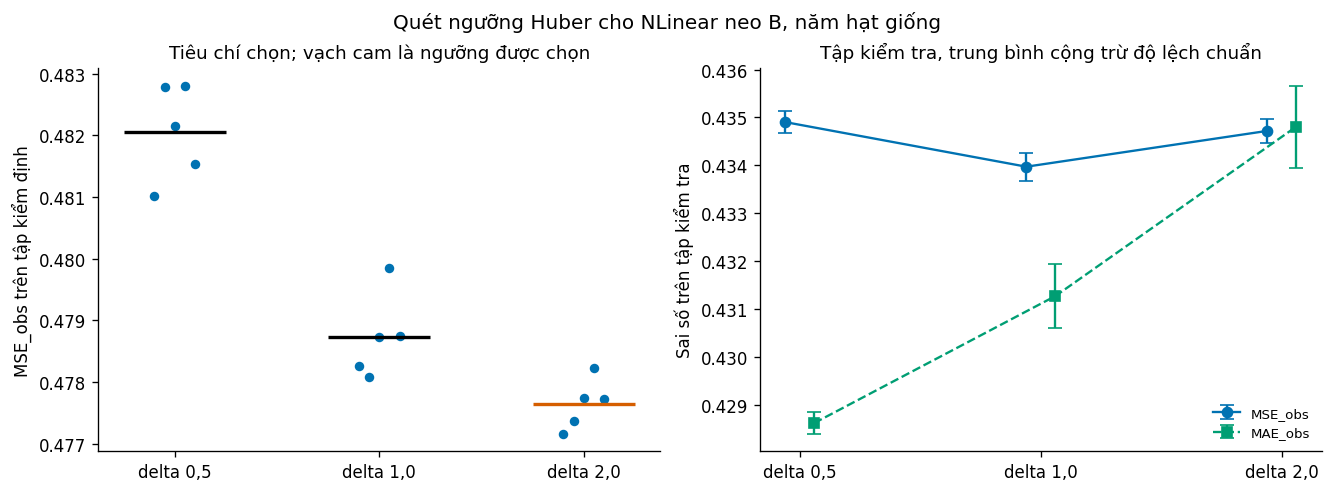

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0))
for i, dl in enumerate(DELTAS):
    v = np.asarray([d["val_mse_obs"] for d in KQ[dl]])
    ax[0].scatter(np.full(v.size, i) + np.linspace(-0.1, 0.1, v.size), v, s=22, color=PALETTE[0])
    ax[0].hlines(v.mean(), i - 0.25, i + 0.25, color=PALETTE[1] if dl == DELTA_CHON else PALETTE[6], lw=2.0)
ax[0].set_xticks(range(len(DELTAS)))
ax[0].set_xticklabels(["delta " + str(d).replace(".", ",") for d in DELTAS])
ax[0].set_ylabel("MSE_obs trên tập kiểm định")
ax[0].set_title("Tiêu chí chọn; vạch cam là ngưỡng được chọn")
x = np.arange(len(DELTAS))
mse_tb = [h["test_mse_tb"] for h in BANG]
mse_sd = [h["test_mse_sd"] for h in BANG]
mae_tb = [h["test_mae_tb"] for h in BANG]
mae_sd = [h["test_mae_sd"] for h in BANG]
ax[1].errorbar(x - 0.06, mse_tb, yerr=mse_sd, fmt="o-", color=PALETTE[0], capsize=4, label="MSE_obs")
ax[1].errorbar(x + 0.06, mae_tb, yerr=mae_sd, fmt="s--", color=PALETTE[2], capsize=4, label="MAE_obs")
ax[1].set_xticks(x)
ax[1].set_xticklabels(["delta " + str(d).replace(".", ",") for d in DELTAS])
ax[1].set_ylabel("Sai số trên tập kiểm tra")
ax[1].set_title("Tập kiểm tra, trung bình cộng trừ độ lệch chuẩn")
ax[1].legend(fontsize=8)
fig.suptitle("Quét ngưỡng Huber cho NLinear neo B, năm hạt giống")
luu_hinh(fig, "W4_35_quet_delta_huber.png")
plt.show()

## 10. Ghi tệp tổng hợp

In [16]:
TONG_HOP = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "so_tay": "W4_35", "run_tag": RUN_TAG, "read_tag": READ_TAG,
    "ma_bam_khai_bao": KHAI_BAO["ma_bam"], "tong_diem": TONG_DIEM_TEST,
    "mse_persistence": MSE_MOC, "mae_persistence": MAE_MOC,
    "luoi_delta": DELTAS, "tieu_chi_chon": KHAI_BAO["quy_tac"]["chon_delta"],
    "bang": BANG, "delta_chon": DELTA_CHON, "tai_lap_tuan_3": TAI_LAP,
    "kiem_dinh_mo_ta": KD_MO_TA,
    "tep_theo_delta": {str(k): [str(p) for p in v] for k, v in TEP.items()},
    "env": ENV,
}
DICH = RUN_DIR / "W4_quet_delta_huber.json"
DICH.write_text(json.dumps(TONG_HOP, ensure_ascii=False, indent=1), encoding="utf-8")
print("Đã ghi", DICH.name, "| ngưỡng chọn:", DELTA_CHON)
print("Bước kế tiếp: chạy notebook 29")

Đã ghi W4_quet_delta_huber.json | ngưỡng chọn: 2.0
Bước kế tiếp: chạy notebook 29
